# Could a student rebuild Orbital Insight's car counter today?
**Group [N], question A.** We reuse a free, open detector (Ultralytics YOLO11, pretrained on the public DOTA aerial-image dataset) **without training it**. Then we:
1. measure it against cars marked by hand in **COWC** (Potsdam tile 2_12, 113 cars), and
2. count the cars in a free **IGN** aerial photo of the Auchan Englos retail park near Lille.

If this works in an afternoon on free tools, the AI model was never Orbital Insight's moat.
*Runtime: about 2 minutes on a Colab GPU (Runtime > Change runtime type > T4 GPU), about 10 minutes on CPU.*

In [1]:
!pip -q install ultralytics

In [2]:
# carcount.py
"""Car counting from overhead images with an open, pretrained detector.

Detector: Ultralytics YOLO11 oriented-box model pretrained on DOTA v1
(aerial images, class "small vehicle" = cars). We do NOT train anything:
the point is to test whether an off-the-shelf open model is enough.
"""
import numpy as np
from PIL import Image
from scipy import ndimage
from scipy.optimize import linear_sum_assignment

Image.MAX_IMAGE_PIXELS = None


def load_rgb(path):
    return np.array(Image.open(path).convert("RGB"))


def car_class_ids(model):
    return [i for i, n in model.names.items() if n.replace("-", " ").lower() == "small vehicle"]


def enhance(im):
    """Stretch contrast and sharpen: helps on hazy, compressed aerial photos."""
    from PIL import ImageOps, ImageFilter
    im = ImageOps.autocontrast(im, cutoff=1)
    return im.filter(ImageFilter.UnsharpMask(radius=3, percent=150, threshold=2))


def detect_cars(model, img, scale=1.0, tile=1024, overlap=160, conf=0.25, imgsz=1024, dedup_px=10, sharpen=False):
    """Run the detector on a large image by tiling it.

    scale: resize factor applied before detection (to match the detector's preferred car size).
    dedup_px: two detections closer than this (original pixels) are the same car.
    Returns an array (N, 4): x, y, confidence, box length (all in ORIGINAL image pixels).
    """
    h0, w0 = img.shape[:2]
    pil = Image.fromarray(img)
    if scale != 1.0:
        pil = pil.resize((int(w0 * scale), int(h0 * scale)), Image.LANCZOS)
    if sharpen:
        pil = enhance(pil)
    im = np.array(pil)
    h, w = im.shape[:2]
    step = tile - overlap
    cls = car_class_ids(model)
    out = []
    ys = list(range(0, max(h - overlap, 1), step))
    xs = list(range(0, max(w - overlap, 1), step))
    for y in ys:
        for x in xs:
            crop = im[y:y + tile, x:x + tile]
            if crop.shape[0] < 32 or crop.shape[1] < 32:
                continue
            r = model.predict(crop, imgsz=imgsz, conf=conf, classes=cls, verbose=False)[0]
            if r.obb is None or len(r.obb) == 0:
                continue
            xywhr = r.obb.xywhr.cpu().numpy()
            cf = r.obb.conf.cpu().numpy()
            for (cx, cy, bw, bh, _), c in zip(xywhr, cf):
                out.append((x + cx, y + cy, c, max(bw, bh)))
    if not out:
        return np.zeros((0, 4))
    d = np.array(out, dtype=float)
    # merge duplicates from overlapping tiles: keep highest confidence within dedup_px
    dedup_px = dedup_px * scale          # given in original-image pixels
    from scipy.spatial import cKDTree
    order = np.argsort(-d[:, 2])
    tree = cKDTree(d[:, :2])
    removed = np.zeros(len(d), bool)
    keep = []
    for i in order:                       # greedy: keep the most confident, drop its neighbours
        if removed[i]:
            continue
        keep.append(i)
        for j in tree.query_ball_point(d[i, :2], dedup_px):
            removed[j] = True
    d = d[keep]
    d[:, :2] /= scale
    d[:, 3] /= scale
    return d


def gt_points(annot_path):
    """COWC ground truth: one small mark at the centre of every car."""
    a = np.array(Image.open(annot_path))
    if a.ndim == 3:
        a = a[..., :3].max(axis=2) if a.shape[2] >= 3 else a[..., 0]
    lab, n = ndimage.label(a > 0)
    if n == 0:
        return np.zeros((0, 2))
    c = ndimage.center_of_mass(np.ones_like(lab), lab, range(1, n + 1))
    return np.array([(x, y) for y, x in c])


def match(det_xy, gt_xy, radius):
    """One-to-one matching of detections to true cars within `radius` pixels."""
    if len(det_xy) == 0 or len(gt_xy) == 0:
        return 0, len(det_xy), len(gt_xy)
    D = np.hypot(det_xy[:, None, 0] - gt_xy[None, :, 0], det_xy[:, None, 1] - gt_xy[None, :, 1])
    cost = np.where(D <= radius, D, 1e6)
    r, c = linear_sum_assignment(cost)
    tp = int((cost[r, c] < 1e6).sum())
    return tp, len(det_xy) - tp, len(gt_xy) - tp


def draw(img, det_xy, gt_xy=None, matched=None, r=9, path=None, max_side=2400):
    """Save a picture with detections (blue rings) and, if given, true cars (orange dots)."""
    from PIL import ImageDraw
    im = Image.fromarray(img).copy()
    dr = ImageDraw.Draw(im)
    if gt_xy is not None:
        for x, y in gt_xy:
            dr.ellipse([x - 3, y - 3, x + 3, y + 3], fill=(235, 104, 52))
    for x, y in det_xy:
        dr.ellipse([x - r, y - r, x + r, y + r], outline=(42, 120, 214), width=3)
    if max(im.size) > max_side:
        f = max_side / max(im.size)
        im = im.resize((int(im.size[0] * f), int(im.size[1] * f)), Image.LANCZOS)
    if path:
        im.save(path, quality=88)
    return im


## 1. Get the data (all free, no login)

In [3]:
import os, urllib.request
COWC = "https://gdo152.llnl.gov/cowc/download/cowc/datasets/ground_truth_sets/Potsdam_ISPRS/"
files = {"top_potsdam_2_12_RGB.png": COWC + "top_potsdam_2_12_RGB.png",
         "top_potsdam_2_12_RGB_Annotated_Cars.png": COWC + "top_potsdam_2_12_RGB_Annotated_Cars.png"}
# IGN BD ORTHO via the free Geoplateforme WMS: ~700 m x 700 m around Auchan Englos.
# We tested on a 2576-px copy of this area (~0.25 m per pixel). If yours differs, set IGN_GSD below.
files["auchan_englos.jpg"] = ("https://data.geopf.fr/wms-r/wms?SERVICE=WMS&VERSION=1.3.0&REQUEST=GetMap"
    "&LAYERS=ORTHOIMAGERY.ORTHOPHOTOS&STYLES=&CRS=EPSG:4326&BBOX=50.62586,2.96105,50.63214,2.97095"
    "&WIDTH=2576&HEIGHT=2576&FORMAT=image/jpeg")
for name, url in files.items():
    if not os.path.exists(name):
        try:
            urllib.request.urlretrieve(url, name); print("downloaded", name)
        except Exception as e:
            print("could not download", name, "->", e, "(upload it with the Files panel)")
print({f: os.path.exists(f) for f in files})

{'top_potsdam_2_12_RGB.png': True, 'top_potsdam_2_12_RGB_Annotated_Cars.png': True, 'auchan_englos.jpg': True}


## 2. Accuracy on COWC (cars marked by hand)

In [4]:
from ultralytics import YOLO
model = YOLO("yolo11m-obb.pt")          # downloads the free pretrained weights
COWC_GSD = 300 / 2220                   # Potsdam tile = 300 m across, 2220 px  ->  0.135 m per pixel
R = 1.5 / COWC_GSD                      # a detection counts if within 1.5 m of a marked car
img = load_rgb("top_potsdam_2_12_RGB.png"); gt = gt_points("top_potsdam_2_12_RGB_Annotated_Cars.png")
for s in (1.0, 1.5, 2.0):
    d = detect_cars(model, img, scale=s, conf=0.25, dedup_px=R)
    tp, fp, fn = match(d[:, :2], gt, R)
    print(f"zoom x{s}: marked cars {len(gt)}, counted {len(d)}, right {tp}, false alarms {fp}, missed {fn}, "
          f"precision {tp/(tp+fp):.0%}, recall {tp/(tp+fn):.0%}")

zoom x1.0: marked cars 113, counted 81, right 75, false alarms 6, missed 38, precision 93%, recall 66%


zoom x1.5: marked cars 113, counted 98, right 92, false alarms 6, missed 21, precision 94%, recall 81%


zoom x2.0: marked cars 113, counted 93, right 88, false alarms 5, missed 25, precision 95%, recall 78%


Chosen setting (zoom x1.5): 92/113 cars found, 6 false alarms


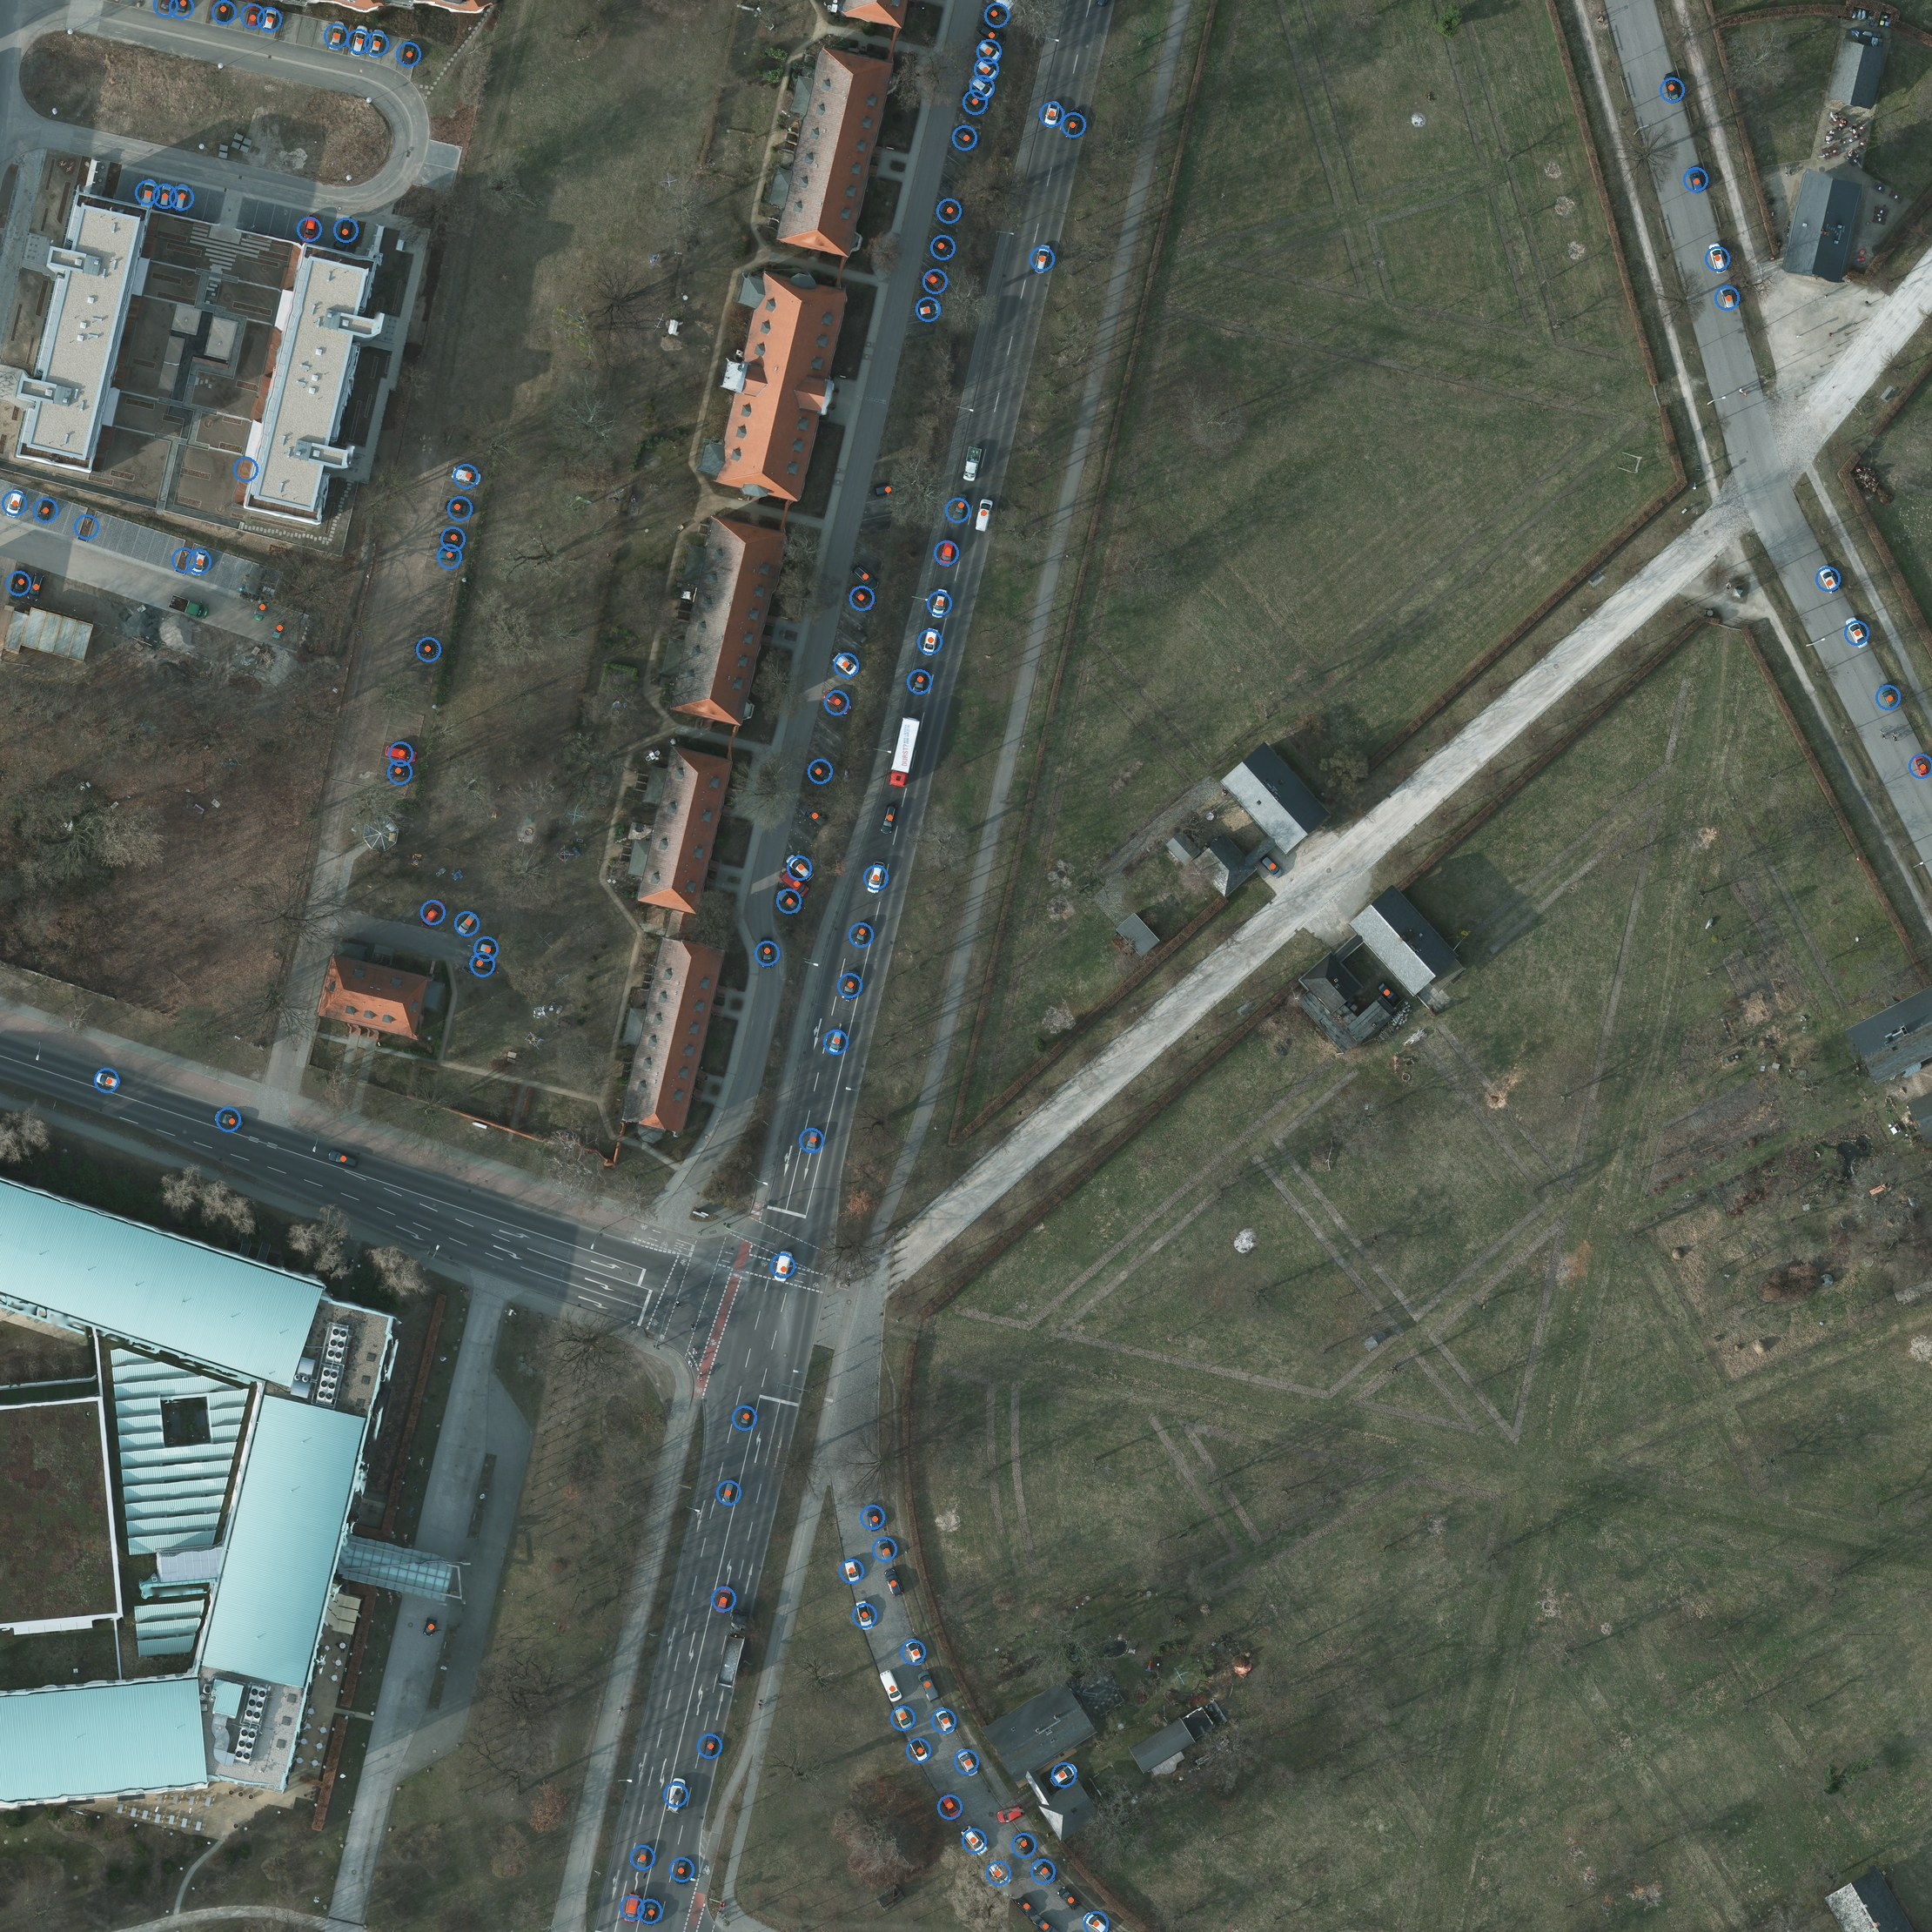

In [5]:
d = detect_cars(model, img, scale=1.5, conf=0.25, dedup_px=R)
tp, fp, fn = match(d[:, :2], gt, R)
assert len(gt) == 113, "the hand labels should contain 113 cars"
print(f"Chosen setting (zoom x1.5): {tp}/{len(gt)} cars found, {fp} false alarms")
draw(img, d[:, :2], gt, r=14, path="cowc_result.jpg")   # orange dot = marked car, blue ring = detection
from IPython.display import Image as Show; Show("cowc_result.jpg", width=700)

## 3. Count the cars at Auchan Englos (IGN, free)

Cars counted: 2217
Check: median car length = 4.4 m (should be ~4-5 m)


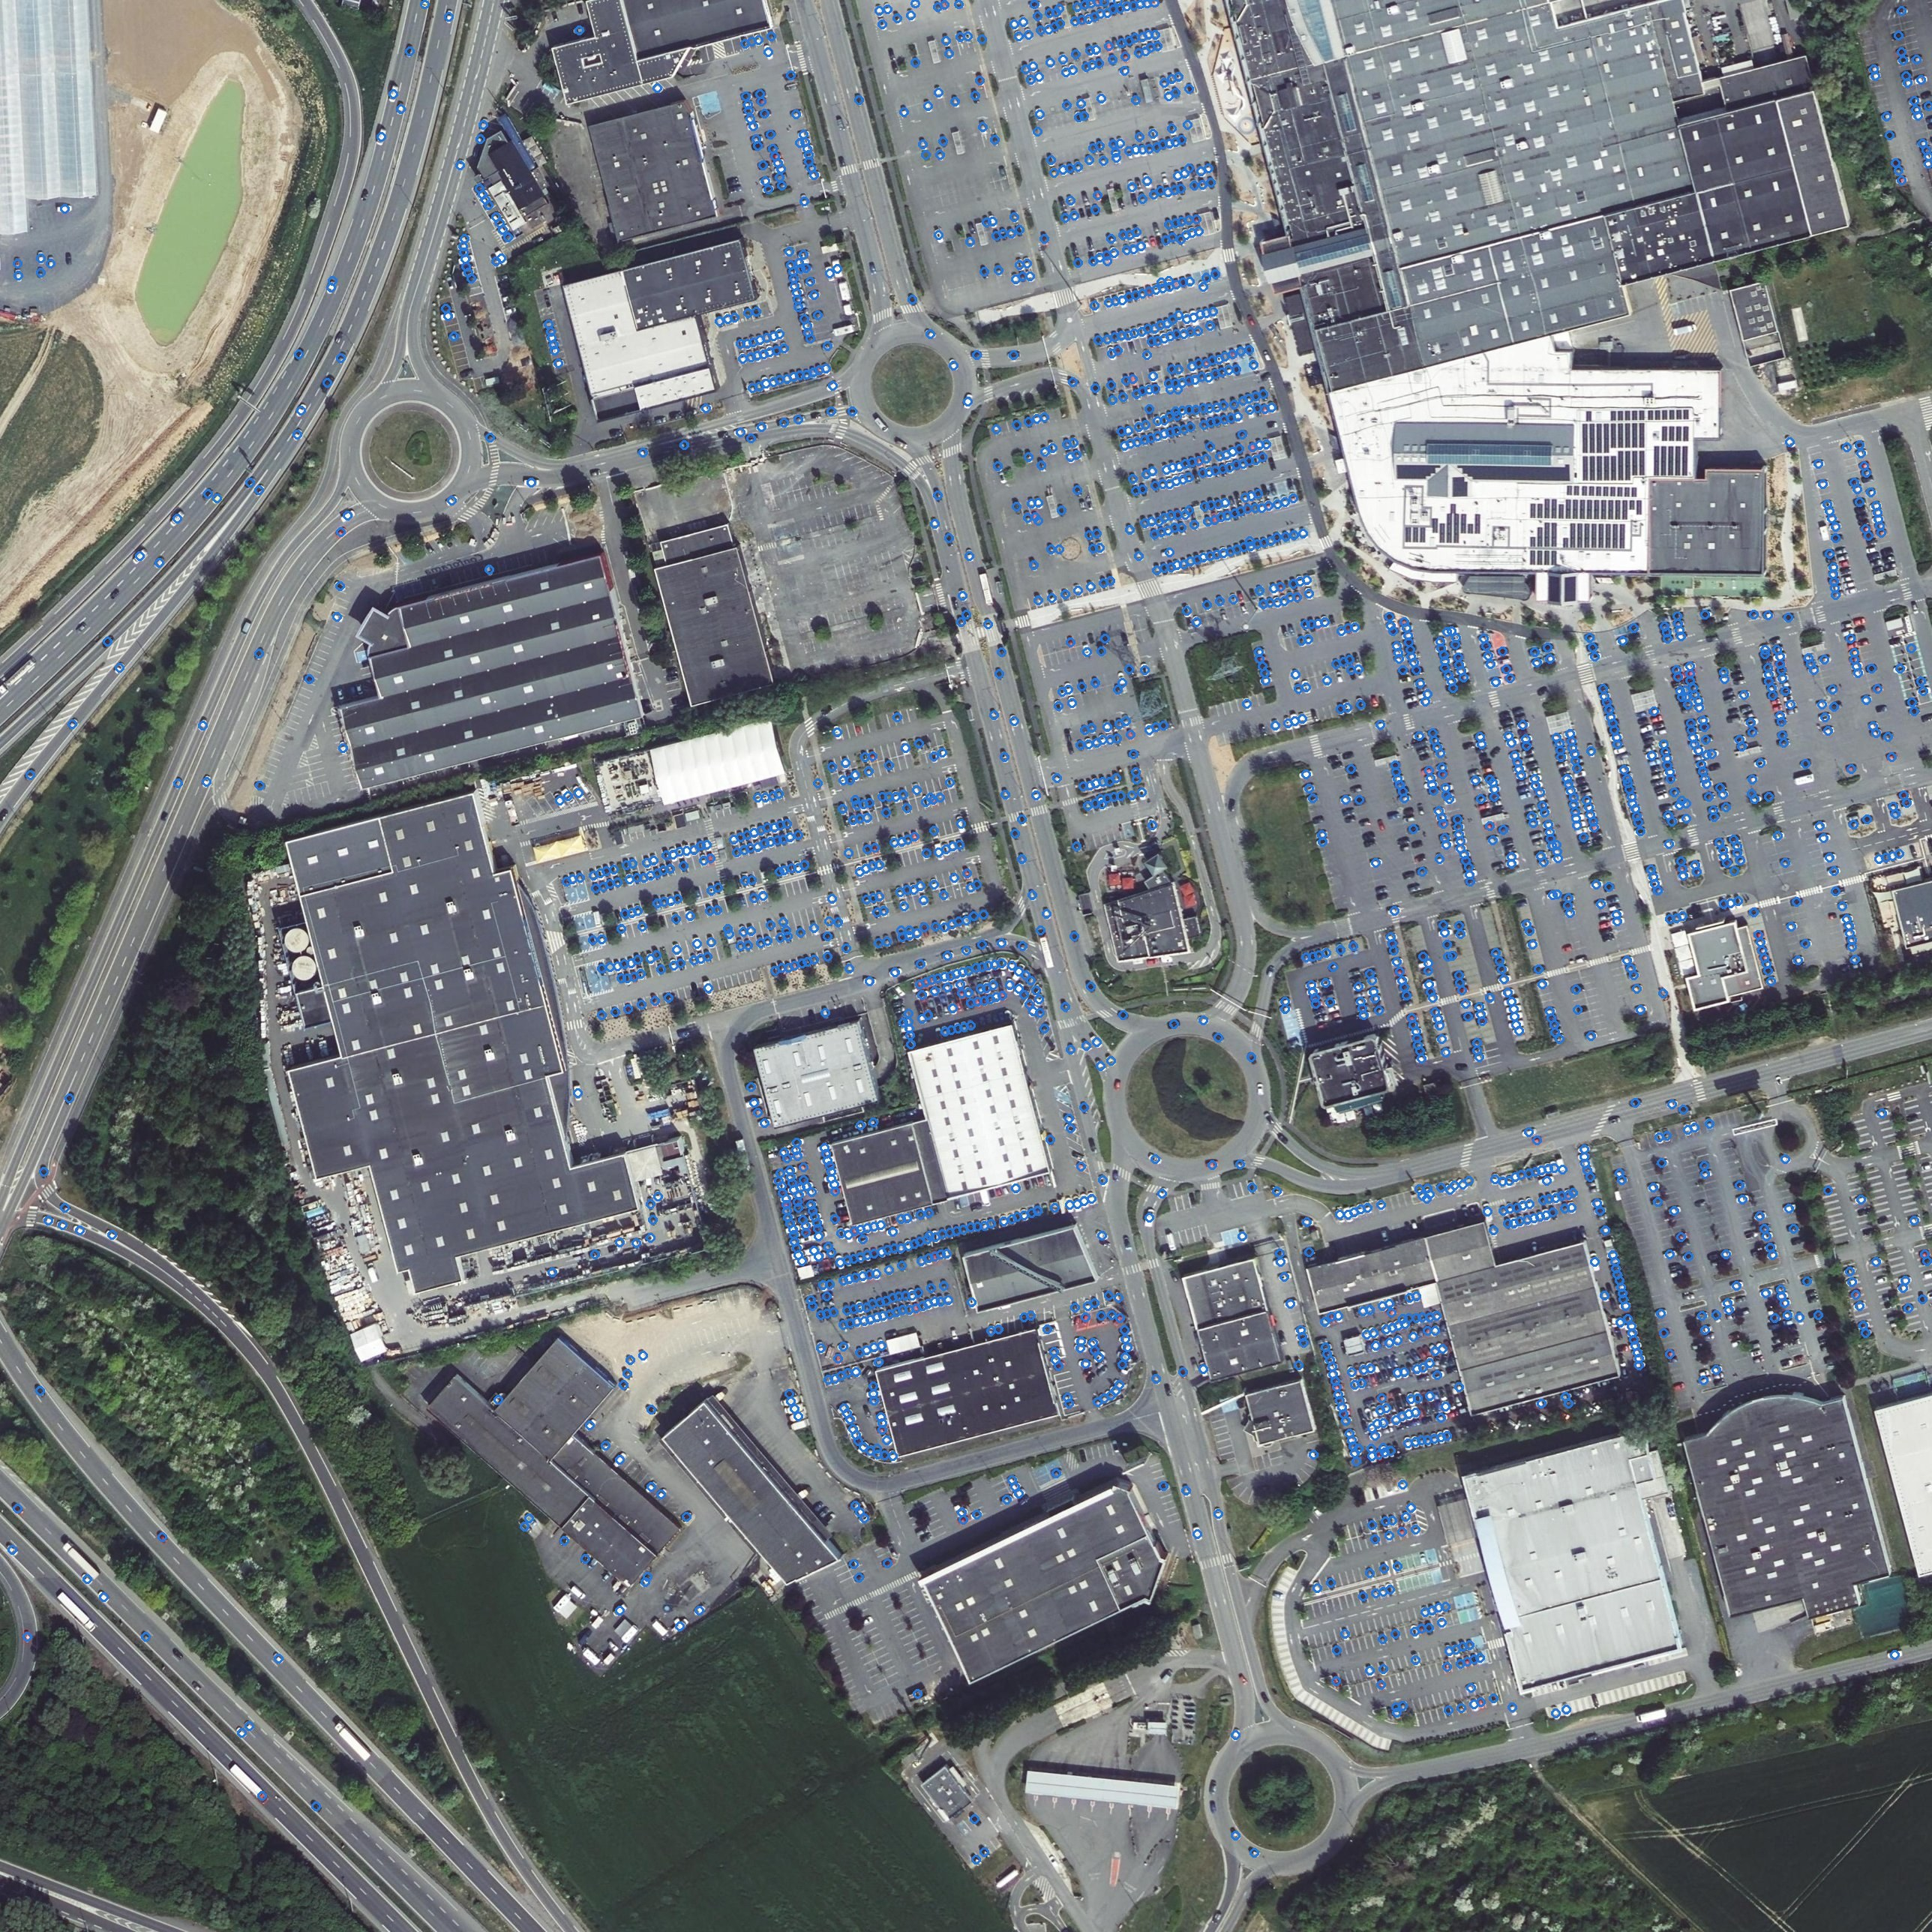

In [6]:
import numpy as np
IGN_GSD = 0.25        # metres per pixel of your IGN image (cars are ~4.4 m long)
SCALE = 5 * IGN_GSD / 0.25   # zoom so a car is ~85 px long, the size that worked on our hand check
ign = load_rgb("auchan_englos.jpg")
cars = detect_cars(model, ign, scale=SCALE, sharpen=True, conf=0.2, dedup_px=1.5 / IGN_GSD)
print(f"Cars counted: {len(cars)}")
print(f"Check: median car length = {np.median(cars[:, 3]) * IGN_GSD:.1f} m (should be ~4-5 m)")
draw(ign, cars[:, :2], r=6, path="auchan_result.jpg", max_side=2576)
Show("auchan_result.jpg", width=900)

## 4. Hand check
COWC has no labels for Englos, so we checked one area (pixels x 1300–1700, y 700–1000) by eye: about **103 cars**, of which **89** were found, **1** false alarm and **14** missed (mostly dark cars in shadow). That gives ~99% precision and ~86% recall on IGN imagery.

**What we learned.** The free model finds most cars on both sources. But the settings that worked on one source (zoom, sharpening) failed on the other until we tuned them by hand. Sharpening helped IGN and hurt COWC. The know-how sits in matching the model to each image supplier, and in having images often enough. An IGN photo is taken every ~3 years, while Orbital Insight bought near-daily imagery.